# Place-Level Emotional Drift Analysis of TripAdvisor Reviews (2019–2024)

## 1. Introduction

This notebook extends the city-level emotional drift analysis by investigating changes in tourist emotions at individual attractions.

The study covers 10 tourist destinations and 48 attractions using TripAdvisor reviews collected between 2019 and 2024.

The main objective is to understand whether emotional changes detected at the city level are shared across attractions or mainly influenced by particular places.

Special attention is given to two previously identified extreme drift episodes:

- Miami: November to December 2020
- Marrakech: November to December 2024

The analysis considers review counts, emotion distributions, changes over time, and the contribution of individual attractions to city-level patterns.

The findings will help explain the results of the city-level analysis and identify possible limitations caused by uneven review coverage.

In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project directories
project_dir = Path.cwd()
results_dir = project_dir / "results"
figures_dir = project_dir / "figures" / "place_level"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Find the original emotion dataset
data_file = project_dir / "Tourism_Reviews_Emotion.csv"

if not data_file.exists():
    raise FileNotFoundError(
        f"Emotion dataset not found: {data_file}"
    )

# Load review-level emotion data
reviews = pd.read_csv(data_file)

print("Dataset shape:", reviews.shape)
print("Cities:", reviews["City"].nunique())
print("Attractions:", reviews["Place"].nunique())

display(reviews.head())


Dataset shape: (22092, 30)
Cities: 10
Attractions: 48


,City,Place,Page,Review_Text,Review_Date,Reviewer_Location,Rating,Year,Month,Month_Year,...,Translation_Status,Anger,Disgust,Fear,Joy,Neutral,Sadness,Surprise,Dominant_Emotion,Dominant_Emotion_Score
0,Agra,Taj Mahal,0,An amazing experience,2019-02-17,Unknown,5,2019,2,2019-02,...,Not Required,0.005210,0.003741,0.030083,0.485461,0.052319,0.008267,0.414919,joy,0.485461
1,Agra,Taj Mahal,0,Awesome place,2019-02-17,"Dharmendra Pahadiya Pune, India",5,2019,2,2019-02,...,Not Required,0.003087,0.002857,0.003248,0.797196,0.060793,0.003041,0.129778,joy,0.797196
2,Agra,Taj Mahal,0,Definitely a wonder of the world,2019-02-17,Unknown,5,2019,2,2019-02,...,Not Required,0.004154,0.002859,0.006706,0.015445,0.052878,0.002578,0.915380,surprise,0.915380
3,Agra,Taj Mahal,0,Mesmerizing,2019-02-16,Unknown,5,2019,2,2019-02,...,Processed,0.015222,0.049447,0.011290,0.022652,0.864298,0.023749,0.013341,neutral,0.864298
4,Agra,Taj Mahal,0,A place really called as wonder,2019-02-16,Unknown,5,2019,2,2019-02,...,Not Required,0.001923,0.000642,0.003407,0.008736,0.005524,0.001576,0.978191,surprise,0.978191


## 2. Data Validation and Cleaning

Before starting the place-level emotional drift analysis, the dataset is checked to ensure that the data is suitable for analysis.

The following checks are performed:

- Missing or empty review text
- Duplicate review IDs
- Missing review dates and attraction names
- Valid emotion probability scores
- Total number of reviews, cities, and attractions

Reviews with empty model text are excluded because their emotion predictions may not be reliable.

The same cleaning rules are used as in the city-level analysis to keep the results consistent.

The original dataset is not modified.

In [34]:

# Validate emotion probabilities
emotion_scores = place_df[emotion_cols]

invalid_emotions = (
    emotion_scores.isna().any(axis=1)
    | ~((emotion_scores >= 0) & (emotion_scores <= 1)).all(axis=1)
    | ~np.isclose(
        emotion_scores.sum(axis=1),
        1.0,
        atol=1e-4
    )
)

print("Invalid emotion distributions:", invalid_emotions.sum())

print("\nFINAL DATASET")
print("Usable reviews:", len(place_df))
print("Cities:", place_df["City"].nunique())
print("Attractions:",
      place_df[["City", "Place"]].drop_duplicates().shape[0])

print("First date:", place_df["Review_Date"].min())
print("Last date:", place_df["Review_Date"].max())


Invalid emotion distributions: 0

FINAL DATASET
Usable reviews: 22085
Cities: 10
Attractions: 48
First date: 2019-01-03 00:00:00
Last date: 2024-12-31 00:00:00


## 3. Attraction-Level Review Coverage

This section examines the number of reviews available for each tourist attraction between 2019 and 2024.

The analysis checks the total number of reviews, the number of months with reviews, and the number of months meeting different minimum review thresholds.

This helps identify attractions with enough data for monthly emotional drift analysis and highlights gaps in the dataset.

In [35]:

# Count reviews for each attraction and month
place_counts = (
    place_df.groupby(["City", "Place", "Month_Year"])
    .size()
    .reset_index(name="Review_Count")
)

# Summarize review coverage for each attraction
place_coverage = (
    place_counts.groupby(["City", "Place"])
    .agg(
        Total_Reviews=("Review_Count", "sum"),
        Months_With_Reviews=("Month_Year", "nunique"),
        Months_ge_5=("Review_Count", lambda x: (x >= 5).sum()),
        Months_ge_10=("Review_Count", lambda x: (x >= 10).sum()),
        Months_ge_20=("Review_Count", lambda x: (x >= 20).sum())
    )
    .reset_index()
)

# Study period contains 72 calendar months
place_coverage["Months_Without_Reviews"] = (
    72 - place_coverage["Months_With_Reviews"]
)

# Sort by city and attraction
place_coverage = place_coverage.sort_values(
    ["City", "Place"]
).reset_index(drop=True)

print("Total attractions:", len(place_coverage))
print("Total reviews:", place_coverage["Total_Reviews"].sum())

display(place_coverage)


Total attractions: 48
Total reviews: 22085


,City,Place,Total_Reviews,Months_With_Reviews,Months_ge_5,Months_ge_10,Months_ge_20,Months_Without_Reviews
0,Agra,Agra Fort,365,53,27,9,5,19
1,Agra,Mehtab Bagh,159,35,13,5,1,37
2,Agra,Taj Mahal,599,48,40,25,5,24
3,Agra,Wildlife SOS,219,44,12,6,2,28
4,Bali,Lempuyang Temple,284,50,19,7,4,22
5,Bali,Mount Batur,409,53,29,17,5,19
6,Bali,Sacred Monkey Forest Sanctuary,478,47,30,22,4,25
7,Bali,Tegallalang Rice Terrace,480,53,32,13,5,19
8,Bali,Uluwatu Temple,480,56,35,19,4,16
9,Barcelona,Casa Batlló,639,27,24,21,15,45


## 4. Minimum Review Threshold Analysis

Monthly emotional drift analysis requires enough reviews to estimate an emotion distribution.

At the attraction level, some months contain only a small number of reviews. This may make the results less stable.

We compare minimum thresholds of 5, 10 and 20 reviews per attraction-month. The comparison helps us choose a suitable threshold while keeping enough data for analysis.

The final threshold will be selected based on data coverage and will be checked through sensitivity analysis.

In [36]:

# Compare minimum monthly review thresholds
threshold_results = []

for threshold in [5, 10, 20]:
    valid = place_counts[
        place_counts["Review_Count"] >= threshold
    ].copy()

    # Count only truly consecutive calendar-month pairs
    valid["Month_Year"] = pd.to_datetime(valid["Month_Year"])
    valid = valid.sort_values(["City", "Place", "Month_Year"])

    previous = valid.groupby(["City", "Place"])["Month_Year"].shift(1)

    month_gap = (
        (valid["Month_Year"].dt.year - previous.dt.year) * 12
        + valid["Month_Year"].dt.month
        - previous.dt.month
    )

    threshold_results.append({
        "Minimum_Reviews": threshold,
        "Valid_Place_Months": len(valid),
        "Attractions_With_Valid_Months":
            valid[["City", "Place"]].drop_duplicates().shape[0],
        "Consecutive_Month_Pairs": (month_gap == 1).sum(),
        "Coverage_Percentage":
            round(100 * len(valid) / len(place_counts), 2)
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary)


,Minimum_Reviews,Valid_Place_Months,Attractions_With_Valid_Months,Consecutive_Month_Pairs,Coverage_Percentage
0,5,1467,48,950,63.26
1,10,870,48,421,37.52
2,20,283,47,80,12.20


## 5. Monthly Emotion Profiles at Attraction Level

This step calculates the average emotion distribution for each attraction in each month.

We group the reviews by city, attraction and month. For each group, we calculate the number of reviews and the average probability of seven emotions: anger, disgust, fear, joy, neutral, sadness and surprise.

We keep months with at least five reviews for the primary exploratory analysis. Thresholds of 10 and 20 reviews will be used later to check the stability of the results.

These monthly profiles will be used to measure emotional drift between consecutive months.

In [37]:

# Step 5: Monthly emotion aggregation

import pandas as pd
import numpy as np

emotion_cols = [
    "Anger", "Disgust", "Fear", "Joy",
    "Neutral", "Sadness", "Surprise"
]

# Use the cleaned review-level dataset from Step 2
monthly_place = (
    place_df
    .groupby(["City", "Place", "Month_Year"])
    .agg(
        Review_Count=("Review_ID", "count"),
        **{emotion: (emotion, "mean")
           for emotion in emotion_cols}
    )
    .reset_index()
)

monthly_place["Month_Year"] = pd.to_datetime(
    monthly_place["Month_Year"]
)

monthly_place = monthly_place.sort_values(
    ["City", "Place", "Month_Year"]
).reset_index(drop=True)

# Check that emotion probabilities sum to approximately 1
monthly_place["Emotion_Total"] = (
    monthly_place[emotion_cols].sum(axis=1)
)

print("Total monthly attraction profiles:", len(monthly_place))
print("Attractions:",
      monthly_place[["City", "Place"]].drop_duplicates().shape[0])

print("Invalid emotion totals:",
      (~np.isclose(monthly_place["Emotion_Total"], 1.0,
                   atol=1e-4)).sum())

# Primary exploratory threshold
monthly_place_valid = monthly_place[
    monthly_place["Review_Count"] >= 5
].copy()

print("Valid profiles (minimum 5 reviews):",
      len(monthly_place_valid))

display(monthly_place_valid.head(10))


Total monthly attraction profiles: 2319
Attractions: 48
Invalid emotion totals: 0
Valid profiles (minimum 5 reviews): 1467


,City,Place,Month_Year,Review_Count,Anger,Disgust,Fear,Joy,Neutral,Sadness,Surprise,Emotion_Total
0,Agra,Agra Fort,2019-02-01,27,0.059513,0.026993,0.016378,0.302728,0.370470,0.018305,0.205614,1.0
1,Agra,Agra Fort,2019-03-01,33,0.015973,0.056560,0.050417,0.407169,0.210066,0.074456,0.185359,1.0
2,Agra,Agra Fort,2019-04-01,10,0.012918,0.051369,0.102884,0.182439,0.417373,0.048396,0.184620,1.0
3,Agra,Agra Fort,2019-05-01,25,0.058380,0.053414,0.110628,0.247768,0.226668,0.092166,0.210977,1.0
4,Agra,Agra Fort,2019-06-01,5,0.024202,0.069008,0.087386,0.388577,0.092225,0.012830,0.325773,1.0
5,Agra,Agra Fort,2020-02-01,29,0.020003,0.022887,0.021598,0.377618,0.299827,0.020361,0.237706,1.0
6,Agra,Agra Fort,2020-03-01,27,0.034033,0.051400,0.059569,0.241663,0.393948,0.030657,0.188730,1.0
7,Agra,Agra Fort,2020-04-01,12,0.016231,0.034294,0.053428,0.369669,0.301976,0.127627,0.096775,1.0
19,Agra,Agra Fort,2022-03-01,5,0.011403,0.038697,0.013977,0.320567,0.408534,0.021590,0.185232,1.0
21,Agra,Agra Fort,2022-05-01,7,0.009915,0.005507,0.017310,0.246904,0.318865,0.012100,0.389400,1.0


## 6. Monthly Emotional Drift at Attraction Level

This step measures how the emotion distribution changes from one month to the next for each tourist attraction.

Jensen–Shannon distance is used as the main drift measure, while cosine distance is calculated for comparison.

Only consecutive calendar months with at least five reviews in each month are included. Months with insufficient reviews are excluded to reduce the effect of very small samples.

A higher drift value indicates a larger change in the predicted emotion distribution. It does not necessarily mean that visitor experiences became better or worse.

In [38]:

# Step 6: Calculate attraction-level emotional drift

import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon, cosine

# Start from monthly profiles with at least 5 reviews
place_drift = monthly_place_valid.copy()

place_drift = place_drift.sort_values(
    ["City", "Place", "Month_Year"]
).reset_index(drop=True)

# Identify the previous eligible month for each attraction
groups = place_drift.groupby(["City", "Place"])

place_drift["Previous_Month"] = groups["Month_Year"].shift(1)
place_drift["Previous_Review_Count"] = groups["Review_Count"].shift(1)

# Calculate calendar-month difference
place_drift["Month_Gap"] = (
    (place_drift["Month_Year"].dt.year -
     place_drift["Previous_Month"].dt.year) * 12
    +
    (place_drift["Month_Year"].dt.month -
     place_drift["Previous_Month"].dt.month)
)

# Store the previous month's emotion probabilities
for emotion in emotion_cols:
    place_drift[f"Previous_{emotion}"] = (
        groups[emotion].shift(1)
    )

# Keep only consecutive calendar months
place_drift = place_drift[
    place_drift["Month_Gap"] == 1
].copy()

# Calculate JS and cosine distance
def calculate_distances(row):
    current = row[emotion_cols].to_numpy(dtype=float)
    previous = row[
        [f"Previous_{e}" for e in emotion_cols]
    ].to_numpy(dtype=float)

    js = jensenshannon(previous, current, base=2)
    cos = cosine(previous, current)

    return pd.Series({
        "JS_Drift": js,
        "Cosine_Drift": cos
    })

place_drift[["JS_Drift", "Cosine_Drift"]] = (
    place_drift.apply(calculate_distances, axis=1)
)

# Validate results
print("Total consecutive-month comparisons:", len(place_drift))
print("Attractions represented:",
      place_drift[["City", "Place"]].drop_duplicates().shape[0])

print("Missing JS values:", place_drift["JS_Drift"].isna().sum())
print("Missing cosine values:", place_drift["Cosine_Drift"].isna().sum())

display(
    place_drift[
        [
            "City", "Place", "Previous_Month",
            "Month_Year", "Previous_Review_Count",
            "Review_Count", "JS_Drift", "Cosine_Drift"
        ]
    ].head(15)
)


Total consecutive-month comparisons: 950
Attractions represented: 48
Missing JS values: 0
Missing cosine values: 0


,City,Place,Previous_Month,Month_Year,Previous_Review_Count,Review_Count,JS_Drift,Cosine_Drift
1,Agra,Agra Fort,2019-02-01,2019-03-01,27.0,33,0.235246,0.082308
2,Agra,Agra Fort,2019-03-01,2019-04-01,33.0,10,0.256299,0.188938
3,Agra,Agra Fort,2019-04-01,2019-05-01,10.0,25,0.203294,0.090236
4,Agra,Agra Fort,2019-05-01,2019-06-01,25.0,5,0.269616,0.109376
6,Agra,Agra Fort,2020-02-01,2020-03-01,29.0,27,0.174080,0.057167
7,Agra,Agra Fort,2020-03-01,2020-04-01,27.0,12,0.227413,0.084127
11,Agra,Agra Fort,2022-10-01,2022-11-01,8.0,10,0.263340,0.128132
12,Agra,Agra Fort,2022-11-01,2022-12-01,10.0,6,0.144477,0.044743
13,Agra,Agra Fort,2022-12-01,2023-01-01,6.0,8,0.351140,0.223085
14,Agra,Agra Fort,2023-01-01,2023-02-01,8.0,6,0.378733,0.300396


## 7. Comparison of Emotional Drift Across Attractions

This step compares the average monthly emotional drift across the 48 tourist attractions.

For each attraction, we calculate the number of valid month-to-month comparisons, the mean Jensen–Shannon distance, the median distance and the maximum distance.

The results help identify attractions with relatively high or low emotional variation over time.

Since attractions have different numbers of reviews and valid monthly comparisons, these differences must be interpreted carefully. High drift does not necessarily indicate negative visitor experiences or a significant external event.

In [39]:

# Step 7: Attraction-level emotional drift summary

attraction_summary = (
    place_drift
    .groupby(["City", "Place"])
    .agg(
        Comparisons=("JS_Drift", "count"),
        Mean_JS=("JS_Drift", "mean"),
        Median_JS=("JS_Drift", "median"),
        Std_JS=("JS_Drift", "std"),
        Max_JS=("JS_Drift", "max"),
        Mean_Cosine=("Cosine_Drift", "mean")
    )
    .reset_index()
)

# Round values for easier reading
numeric_cols = [
    "Mean_JS", "Median_JS", "Std_JS",
    "Max_JS", "Mean_Cosine"
]

attraction_summary[numeric_cols] = (
    attraction_summary[numeric_cols].round(4)
)

# Rank attractions by average emotional drift
attraction_summary = attraction_summary.sort_values(
    "Mean_JS", ascending=False
).reset_index(drop=True)

print("Total attractions:", len(attraction_summary))

print("\nTop 15 attractions by average emotional drift:")
display(attraction_summary.head(15))

print("\nBottom 10 attractions by average emotional drift:")
display(attraction_summary.tail(10))

print("\nNumber of monthly comparisons per attraction:")
display(attraction_summary["Comparisons"].describe())


Total attractions: 48

Top 15 attractions by average emotional drift:


,City,Place,Comparisons,Mean_JS,Median_JS,Std_JS,Max_JS,Mean_Cosine
0,Rio de Janeiro,Escadaria Selarón,14,0.3566,0.3408,0.1224,0.5384,0.2006
1,Rio de Janeiro,Copacabana Beach,13,0.3556,0.3489,0.1787,0.7586,0.1903
2,Miami,Miami Seaquarium,17,0.3304,0.3414,0.1047,0.5278,0.1875
3,Miami,Bayside Marketplace,34,0.3247,0.3271,0.1079,0.5471,0.1603
4,Agra,Wildlife SOS,9,0.3143,0.2295,0.1657,0.6533,0.1724
5,Bali,Lempuyang Temple,8,0.3105,0.2802,0.0928,0.4571,0.1227
6,Bali,Uluwatu Temple,24,0.3088,0.2954,0.1040,0.6089,0.1618
7,Rome,Colosseum,21,0.3040,0.3260,0.0642,0.4234,0.1235
8,Rio de Janeiro,Sugarloaf Mountain,23,0.3001,0.2804,0.1064,0.5575,0.1558
9,Cairo,Coptic Cairo,3,0.2952,0.2920,0.0089,0.3052,0.0986



Bottom 10 attractions by average emotional drift:


,City,Place,Comparisons,Mean_JS,Median_JS,Std_JS,Max_JS,Mean_Cosine
38,Dubai,Dubai Miracle Garden,24,0.2311,0.2309,0.0690,0.3852,0.0745
39,Paris,Notre-Dame Cathedral,23,0.2311,0.2074,0.1109,0.4739,0.1148
40,Paris,Arc de Triomphe,21,0.2298,0.2272,0.0718,0.3430,0.0780
41,Dubai,The Dubai Fountain,21,0.2284,0.2196,0.0853,0.4306,0.0774
42,Rome,Pantheon,34,0.2282,0.2151,0.0986,0.4972,0.0877
43,Barcelona,Park Güell,18,0.2202,0.2178,0.0647,0.3472,0.0944
44,Cairo,Mosque of Muhammad Ali,15,0.2190,0.1913,0.0743,0.3761,0.0980
45,Marrakech,Bahia Palace,23,0.2091,0.2126,0.0801,0.3796,0.0643
46,Barcelona,Casa Batlló,17,0.2013,0.1812,0.0769,0.3726,0.0788
47,Miami,Miami Beach Boardwalk,7,0.1838,0.1712,0.0666,0.3055,0.0521



Number of monthly comparisons per attraction:


count    48.000000
mean     19.791667
std       7.091974
min       3.000000
25%      15.000000
50%      19.500000
75%      23.250000
max      35.000000
Name: Comparisons, dtype: float64

## 8. Comparison of Average Emotional Drift Across Attractions

This figure compares attractions based on their average monthly Jensen–Shannon distance.

Only attractions with at least 10 consecutive-month comparisons are included in the figure to avoid presenting rankings based on very limited observations.

Higher values indicate larger average changes in predicted emotion distributions between consecutive months.

The results are descriptive and do not establish statistical significance or the causes of emotional change.

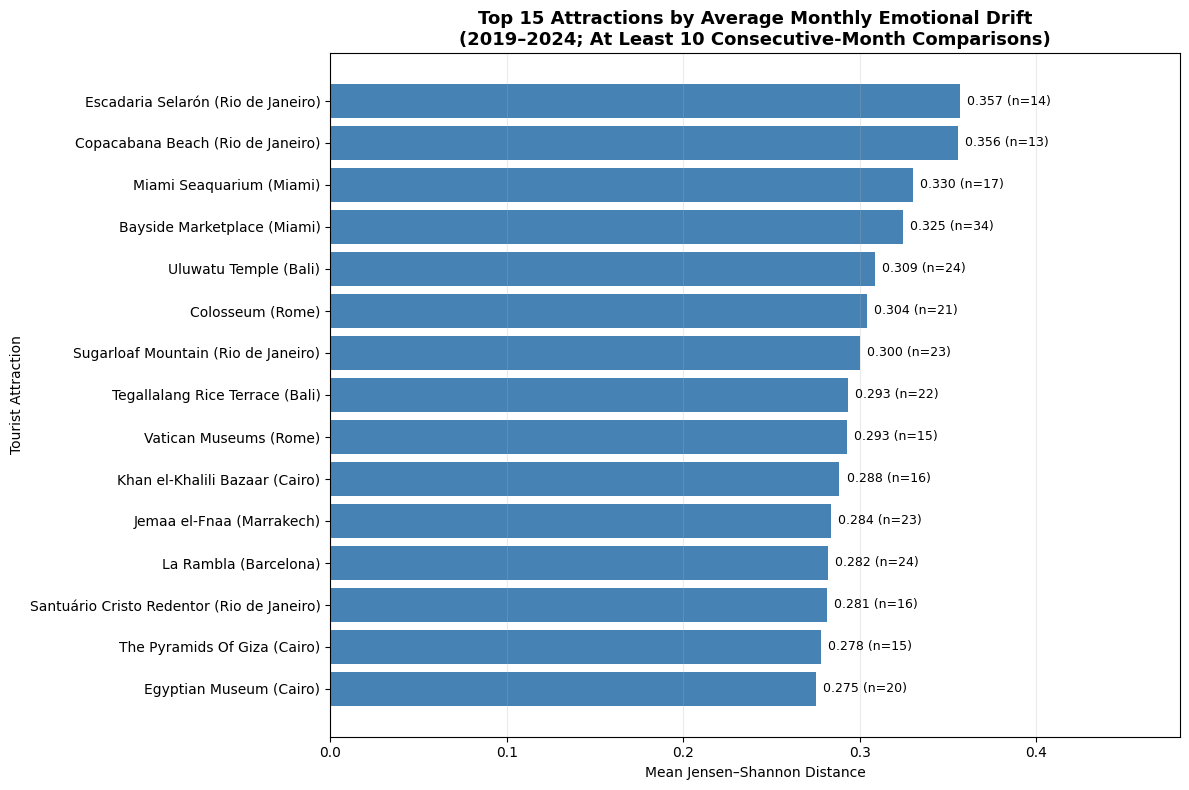

Figure saved successfully.
Eligible attractions: 44


In [40]:

import matplotlib.pyplot as plt

# Keep attractions with at least 10 comparisons
eligible_attractions = attraction_summary[
    attraction_summary["Comparisons"] >= 10
].copy()

# Select the top 15
top_attractions = (
    eligible_attractions
    .sort_values("Mean_JS", ascending=False)
    .head(15)
    .sort_values("Mean_JS")
)

# Create readable labels
labels = (
    top_attractions["Place"]
    + " (" + top_attractions["City"] + ")"
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    labels,
    top_attractions["Mean_JS"],
    color="steelblue"
)

for bar, (_, row) in zip(bars, top_attractions.iterrows()):
    ax.text(
        bar.get_width() + 0.004,
        bar.get_y() + bar.get_height() / 2,
        f'{row["Mean_JS"]:.3f} (n={int(row["Comparisons"])})',
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 15 Attractions by Average Monthly Emotional Drift\n"
    "(2019–2024; At Least 10 Consecutive-Month Comparisons)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Mean Jensen–Shannon Distance")
ax.set_ylabel("Tourist Attraction")
ax.set_xlim(0, top_attractions["Mean_JS"].max() * 1.35)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

# Save the figure
from pathlib import Path

output_dir = Path("figures") / "place_level"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "Attraction_Average_Emotional_Drift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")
print("Eligible attractions:", len(eligible_attractions))


## 9. Detection of Unusual Emotional Drift Episodes

This step identifies months with unusually large emotional changes at individual tourist attractions.

We calculate the median Jensen–Shannon distance and Median Absolute Deviation (MAD) for each attraction. These values are used to calculate a robust Z-score.

A robust Z-score above 3.5 is used to identify extreme drift candidates.

Only attractions with at least 10 valid monthly comparisons are included in this analysis.

The detected episodes are exploratory candidates. Further analysis is required to determine whether they are statistically reliable or related to external events.

In [41]:

# Step 9: Detect extreme attraction-level drift episodes

import numpy as np
import pandas as pd

# Require at least 10 comparisons per attraction
counts = place_drift.groupby(["City", "Place"])["JS_Drift"].transform("count")

spike_data = place_drift[counts >= 10].copy()

# Calculate attraction-specific median
spike_data["Median_JS"] = (
    spike_data.groupby(["City", "Place"])["JS_Drift"]
    .transform("median")
)

# Absolute deviation from the median
spike_data["Absolute_Deviation"] = (
    spike_data["JS_Drift"] - spike_data["Median_JS"]
).abs()

# Median Absolute Deviation
spike_data["MAD_JS"] = (
    spike_data.groupby(["City", "Place"])["Absolute_Deviation"]
    .transform("median")
)

# Robust Z-score; undefined when MAD is zero
spike_data["Robust_Z"] = np.where(
    spike_data["MAD_JS"] > 1e-12,
    0.6745 *
    (spike_data["JS_Drift"] - spike_data["Median_JS"]) /
    spike_data["MAD_JS"].replace(0, np.nan),
    np.nan
)

# Identify extreme positive deviations
spike_data["Is_Spike"] = spike_data["Robust_Z"] > 3.5

extreme_spikes = (
    spike_data[spike_data["Is_Spike"]]
    .sort_values("Robust_Z", ascending=False)
    .copy()
)

print("Comparisons evaluated:", len(spike_data))
print("Attractions evaluated:",
      spike_data[["City", "Place"]].drop_duplicates().shape[0])
print("Undefined robust Z-scores:",
      spike_data["Robust_Z"].isna().sum())
print("Extreme drift candidates:", len(extreme_spikes))

display(
    extreme_spikes[
        [
            "City", "Place", "Previous_Month",
            "Month_Year", "Previous_Review_Count",
            "Review_Count", "JS_Drift", "Robust_Z"
        ]
    ].head(20)
)


Comparisons evaluated: 923
Attractions evaluated: 44
Undefined robust Z-scores: 0
Extreme drift candidates: 14


,City,Place,Previous_Month,Month_Year,Previous_Review_Count,Review_Count,JS_Drift,Robust_Z
1264,Rio de Janeiro,Santuário Cristo Redentor,2024-01-01,2024-02-01,12.0,5,0.598035,7.531352
962,Miami,Wynwood Walls,2021-06-01,2021-07-01,13.0,5,0.640628,5.589633
231,Bali,Uluwatu Temple,2024-03-01,2024-04-01,5.0,7,0.608851,4.719786
963,Miami,Wynwood Walls,2021-07-01,2021-08-01,5.0,7,0.564872,4.542996
824,Marrakech,Saadian Tombs,2024-04-01,2024-05-01,14.0,7,0.455662,4.308805
35,Agra,Mehtab Bagh,2019-09-01,2019-10-01,6.0,10,0.392898,4.207676
1141,Paris,Notre-Dame Cathedral,2020-06-01,2020-07-01,7.0,5,0.473930,4.038636
178,Bali,Tegallalang Rice Terrace,2022-04-01,2022-05-01,9.0,12,0.581454,4.038320
292,Barcelona,La Rambla,2022-05-01,2022-06-01,6.0,5,0.585602,3.970393
1281,Rio de Janeiro,Sugarloaf Mountain,2021-03-01,2021-04-01,9.0,6,0.557508,3.913324


## 10. Sensitivity Analysis of Monthly Review Thresholds

The primary attraction-level analysis uses a minimum of five reviews per month. However, months with small numbers of reviews may produce unstable emotion distributions.

To evaluate the robustness of the findings, we repeat the emotional drift and spike detection analysis using minimum monthly review thresholds of 5, 10 and 20 reviews.

For each threshold, we calculate Jensen–Shannon distance between consecutive months and identify extreme drift episodes using attraction-specific median and MAD.

We compare the number of valid comparisons and detected episodes. A change in the detected episodes may result from reduced data coverage or changes in the attraction's estimated baseline variability.

In [42]:

# Step 10: Review-threshold sensitivity analysis

import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon

# Review thresholds
thresholds = [5, 10, 20]

# Store results
sensitivity_results = []
all_threshold_spikes = []
all_threshold_comparisons = []

for threshold in thresholds:

    # Select attraction-months meeting the threshold
    data = monthly_place[
        monthly_place["Review_Count"] >= threshold
    ].copy()

    data = data.sort_values(
        ["City", "Place", "Month_Year"]
    )

    groups = data.groupby(["City", "Place"])

    # Previous month and review count
    data["Previous_Month"] = groups["Month_Year"].shift(1)

    data["Previous_Review_Count"] = (
        groups["Review_Count"].shift(1)
    )

    # Previous emotion probabilities
    for emotion in emotion_cols:
        data[f"Previous_{emotion}"] = (
            groups[emotion].shift(1)
        )

    # Calculate calendar-month gap
    data["Month_Gap"] = (
        (data["Month_Year"].dt.year -
         data["Previous_Month"].dt.year) * 12
        +
        data["Month_Year"].dt.month -
        data["Previous_Month"].dt.month
    )

    # Only consecutive months
    data = data[
        data["Month_Gap"] == 1
    ].copy()

    if data.empty:
        continue

    # Current and previous emotion distributions
    current = data[
        emotion_cols
    ].to_numpy(dtype=float)

    previous = data[
        [f"Previous_{e}" for e in emotion_cols]
    ].to_numpy(dtype=float)

    # Jensen-Shannon distance
    data["JS_Drift"] = [
        jensenshannon(p, c, base=2)
        for p, c in zip(previous, current)
    ]

    # Require at least 10 comparisons per attraction
    comparison_counts = data.groupby(
        ["City", "Place"]
    )["JS_Drift"].transform("count")

    eligible = data[
        comparison_counts >= 10
    ].copy()

    # Attraction-specific median
    eligible["Median_JS"] = eligible.groupby(
        ["City", "Place"]
    )["JS_Drift"].transform("median")

    # Absolute deviation from median
    eligible["Absolute_Deviation"] = (
        eligible["JS_Drift"] -
        eligible["Median_JS"]
    ).abs()

    # Median absolute deviation (MAD)
    eligible["MAD_JS"] = eligible.groupby(
        ["City", "Place"]
    )["Absolute_Deviation"].transform("median")

    # Robust Z-score
    eligible["Robust_Z"] = (
        0.6745 *
        (eligible["JS_Drift"] - eligible["Median_JS"])
        /
        eligible["MAD_JS"].replace(0, np.nan)
    )

    # Identify extreme drift episodes
    eligible["Is_Spike"] = (
        eligible["Robust_Z"] > 3.5
    )

    # Save threshold information
    eligible["Minimum_Reviews"] = threshold

    # IMPORTANT: Save all eligible comparisons
    all_threshold_comparisons.append(
        eligible.copy()
    )

    # Save detected spikes
    spikes = eligible[
        eligible["Is_Spike"]
    ].copy()

    all_threshold_spikes.append(spikes)

    # Sensitivity summary
    sensitivity_results.append({
        "Minimum_Reviews": threshold,
        "Consecutive_Comparisons": len(data),
        "Attractions_Evaluated": (
            eligible[["City", "Place"]]
            .drop_duplicates()
            .shape[0]
        ),
        "Comparisons_Evaluated": len(eligible),
        "Extreme_Spikes": len(spikes),
        "Spike_Percentage": (
            round(
                100 * len(spikes) / len(eligible),
                2
            )
            if len(eligible) else 0
        )
    })

# Create summary DataFrame
sensitivity_summary = pd.DataFrame(
    sensitivity_results
)

# Combine all eligible comparisons
threshold_comparisons = pd.concat(
    all_threshold_comparisons,
    ignore_index=True
) if all_threshold_comparisons else pd.DataFrame()

# Combine detected spikes
threshold_spikes = pd.concat(
    all_threshold_spikes,
    ignore_index=True
) if all_threshold_spikes else pd.DataFrame()

# Display results
print("REVIEW-THRESHOLD SENSITIVITY ANALYSIS")
display(sensitivity_summary)

print("\nTotal eligible comparisons:",
      len(threshold_comparisons))

print("\nDetected extreme drift episodes:")

if not threshold_spikes.empty:

    display(
        threshold_spikes[
            [
                "Minimum_Reviews",
                "City",
                "Place",
                "Previous_Month",
                "Month_Year",
                "Previous_Review_Count",
                "Review_Count",
                "JS_Drift",
                "Robust_Z"
            ]
        ].sort_values(
            ["Minimum_Reviews", "Robust_Z"],
            ascending=[True, False]
        )
    )

else:
    print("No extreme episodes detected.")


REVIEW-THRESHOLD SENSITIVITY ANALYSIS


,Minimum_Reviews,Consecutive_Comparisons,Attractions_Evaluated,Comparisons_Evaluated,Extreme_Spikes,Spike_Percentage
0,5,950,44,923,14,1.52
1,10,421,17,254,3,1.18
2,20,80,0,0,0,0.00



Total eligible comparisons: 1177

Detected extreme drift episodes:


,Minimum_Reviews,City,Place,Previous_Month,Month_Year,Previous_Review_Count,Review_Count,JS_Drift,Robust_Z
12,5,Rio de Janeiro,Santuário Cristo Redentor,2024-01-01,2024-02-01,12.0,5,0.598035,7.531352
7,5,Miami,Wynwood Walls,2021-06-01,2021-07-01,13.0,5,0.640628,5.589633
3,5,Bali,Uluwatu Temple,2024-03-01,2024-04-01,5.0,7,0.608851,4.719786
8,5,Miami,Wynwood Walls,2021-07-01,2021-08-01,5.0,7,0.564872,4.542996
6,5,Marrakech,Saadian Tombs,2024-04-01,2024-05-01,14.0,7,0.455662,4.308805
0,5,Agra,Mehtab Bagh,2019-09-01,2019-10-01,6.0,10,0.392898,4.207676
9,5,Paris,Notre-Dame Cathedral,2020-06-01,2020-07-01,7.0,5,0.473930,4.038636
1,5,Bali,Tegallalang Rice Terrace,2022-04-01,2022-05-01,9.0,12,0.581454,4.038320
4,5,Barcelona,La Rambla,2022-05-01,2022-06-01,6.0,5,0.585602,3.970393
13,5,Rio de Janeiro,Sugarloaf Mountain,2021-03-01,2021-04-01,9.0,6,0.557508,3.913324


In [43]:

# Step 11: Examine extreme spikes at minimum 10 reviews

spikes_10 = threshold_spikes[
    threshold_spikes["Minimum_Reviews"] == 10
].copy()

columns = [
    "City",
    "Place",
    "Previous_Month",
    "Month_Year",
    "Previous_Review_Count",
    "Review_Count",
    "JS_Drift",
    "Robust_Z"
]

display(
    spikes_10[columns]
    .sort_values("Robust_Z", ascending=False)
    .reset_index(drop=True)
)

print("Extreme spikes at threshold 10:", len(spikes_10))


,City,Place,Previous_Month,Month_Year,Previous_Review_Count,Review_Count,JS_Drift,Robust_Z
0,Barcelona,Casa Batlló,2021-12-01,2022-01-01,14.0,19,0.372563,4.676141
1,Marrakech,Jemaa el-Fnaa,2023-08-01,2023-09-01,14.0,10,0.335853,4.323447
2,Barcelona,Casa Batlló,2021-11-01,2021-12-01,17.0,14,0.336288,3.863101


Extreme spikes at threshold 10: 3


### Step 12: Robustness of Attraction-Level Drift Episodes

This step compares the extreme emotional-drift episodes detected using minimum monthly review thresholds of 5 and 10. The aim is to identify whether the same attraction-level changes remain extreme under different review-count requirements.

The analysis distinguishes between episodes that are not detected and episodes that are not eligible for evaluation.

In [44]:

# Compare extreme drift episodes across thresholds

episodes = threshold_spikes[
    threshold_spikes["Minimum_Reviews"].isin([5, 10])
].copy()

comparison = (
    episodes.assign(Detected=1)
    .pivot_table(
        index=["City", "Place", "Previous_Month", "Month_Year"],
        columns="Minimum_Reviews",
        values="Detected",
        aggfunc="max",
        fill_value=0
    )
    .reset_index()
)

comparison.columns.name = None

comparison = comparison.rename(
    columns={
        5: "Detected_at_5",
        10: "Detected_at_10"
    }
)

for col in ["Detected_at_5", "Detected_at_10"]:
    if col not in comparison.columns:
        comparison[col] = 0

comparison["Detected_at_Both"] = (
    (comparison["Detected_at_5"] == 1)
    & (comparison["Detected_at_10"] == 1)
)

display(
    comparison[
        comparison["Detected_at_10"] == 1
    ].sort_values(["City", "Place", "Month_Year"])
)

print(
    "Episodes detected at both thresholds:",
    comparison["Detected_at_Both"].sum()
)


,City,Place,Previous_Month,Month_Year,Detected_at_5,Detected_at_10,Detected_at_Both
4,Barcelona,Casa Batlló,2021-11-01,2021-12-01,0,1,False
5,Barcelona,Casa Batlló,2021-12-01,2022-01-01,0,1,False
8,Marrakech,Jemaa el-Fnaa,2023-08-01,2023-09-01,0,1,False


Episodes detected at both thresholds: 0


### Step 13: Comparison of Robust Z-Scores Across Review Thresholds

This step compares the same attraction-level emotional-drift episodes using minimum monthly review thresholds of 5 and 10.

The aim is to examine how the median, median absolute deviation (MAD), and robust Z-score change with the review threshold.

This analysis helps assess the sensitivity of extreme drift detection to the selected threshold.

In [45]:

# Step 13: Compare extreme episodes across thresholds

# Select episodes detected at threshold 10
targets = threshold_spikes.loc[
    threshold_spikes["Minimum_Reviews"] == 10,
    ["City", "Place", "Previous_Month", "Month_Year"]
].drop_duplicates()

# Retrieve the same episodes at thresholds 5 and 10
comparison = targets.merge(
    threshold_comparisons[
        threshold_comparisons["Minimum_Reviews"].isin([5, 10])
    ][
        [
            "Minimum_Reviews",
            "City",
            "Place",
            "Previous_Month",
            "Month_Year",
            "JS_Drift",
            "Median_JS",
            "MAD_JS",
            "Robust_Z",
            "Is_Spike"
        ]
    ],
    on=["City", "Place", "Previous_Month", "Month_Year"],
    how="left"
)

# Display results in a readable table
comparison = comparison.sort_values(
    ["City", "Place", "Month_Year", "Minimum_Reviews"]
)

display(
    comparison[
        [
            "City",
            "Place",
            "Previous_Month",
            "Month_Year",
            "Minimum_Reviews",
            "JS_Drift",
            "Median_JS",
            "MAD_JS",
            "Robust_Z",
            "Is_Spike"
        ]
    ].round(4)
)

print("Total comparison rows:", len(comparison))


,City,Place,Previous_Month,Month_Year,Minimum_Reviews,JS_Drift,Median_JS,MAD_JS,Robust_Z,Is_Spike
0,Barcelona,Casa Batlló,2021-11-01,2021-12-01,5,0.3363,0.1812,0.0377,2.7732,False
1,Barcelona,Casa Batlló,2021-11-01,2021-12-01,10,0.3363,0.1639,0.0301,3.8631,True
2,Barcelona,Casa Batlló,2021-12-01,2022-01-01,5,0.3726,0.1812,0.0377,3.4220,False
3,Barcelona,Casa Batlló,2021-12-01,2022-01-01,10,0.3726,0.1639,0.0301,4.6761,True
4,Marrakech,Jemaa el-Fnaa,2023-08-01,2023-09-01,5,0.3359,0.3020,0.1128,0.2024,False
5,Marrakech,Jemaa el-Fnaa,2023-08-01,2023-09-01,10,0.3359,0.1701,0.0259,4.3234,True


Total comparison rows: 6


### Step 14: Emotion Changes During Attraction-Level Drift Episodes

This step examines changes in the seven emotion probabilities during the three extreme drift episodes detected using a minimum of 10 reviews per month.

For each episode, the mean emotion probabilities in the previous and current months are compared. The analysis identifies the emotions contributing most to the observed change.

These results describe changes in the review emotion distributions and do not establish the causes of those changes.

In [46]:

# Step 14: Emotion changes in selected attraction-level episodes

emotion_changes = []

for _, episode in spikes_10.iterrows():

    city = episode["City"]
    place = episode["Place"]

    previous_month = pd.to_datetime(
        episode["Previous_Month"]
    )

    current_month = pd.to_datetime(
        episode["Month_Year"]
    )

    previous_data = monthly_place[
        (monthly_place["City"] == city) &
        (monthly_place["Place"] == place) &
        (monthly_place["Month_Year"] == previous_month)
    ]

    current_data = monthly_place[
        (monthly_place["City"] == city) &
        (monthly_place["Place"] == place) &
        (monthly_place["Month_Year"] == current_month)
    ]

    if previous_data.empty or current_data.empty:
        continue

    for emotion in emotion_cols:

        previous_value = previous_data.iloc[0][emotion]
        current_value = current_data.iloc[0][emotion]

        emotion_changes.append({
            "City": city,
            "Place": place,
            "Previous_Month": previous_month,
            "Current_Month": current_month,
            "Emotion": emotion,
            "Previous_Probability": previous_value,
            "Current_Probability": current_value,
            "Change": current_value - previous_value
        })

emotion_changes_df = pd.DataFrame(emotion_changes)

# Find the largest absolute emotion change per episode
emotion_changes_df["Absolute_Change"] = (
    emotion_changes_df["Change"].abs()
)

largest_changes = (
    emotion_changes_df
    .sort_values("Absolute_Change", ascending=False)
    .drop_duplicates(
        ["City", "Place", "Previous_Month", "Current_Month"]
    )
    .sort_values(["City", "Place", "Current_Month"])
)

display(
    largest_changes[
        [
            "City",
            "Place",
            "Previous_Month",
            "Current_Month",
            "Emotion",
            "Previous_Probability",
            "Current_Probability",
            "Change"
        ]
    ].round(4)
)

print("Total emotion-change records:", len(emotion_changes_df))


,City,Place,Previous_Month,Current_Month,Emotion,Previous_Probability,Current_Probability,Change
6,Barcelona,Casa Batlló,2021-11-01,2021-12-01,Surprise,0.1137,0.4198,0.3062
13,Barcelona,Casa Batlló,2021-12-01,2022-01-01,Surprise,0.4198,0.0941,-0.3258
18,Marrakech,Jemaa el-Fnaa,2023-08-01,2023-09-01,Neutral,0.2952,0.5055,0.2103


Total emotion-change records: 21


### Step 15: Visualization of Attraction-Level Emotion Changes

This figure compares the seven average emotion probabilities before and after three selected attraction-level drift episodes.

The analysis includes two consecutive transitions at Casa Batlló in Barcelona and one transition at Jemaa el-Fnaa in Marrakech.

The purpose is to understand how the emotion distributions changed and identify which emotions contributed to the observed drift.

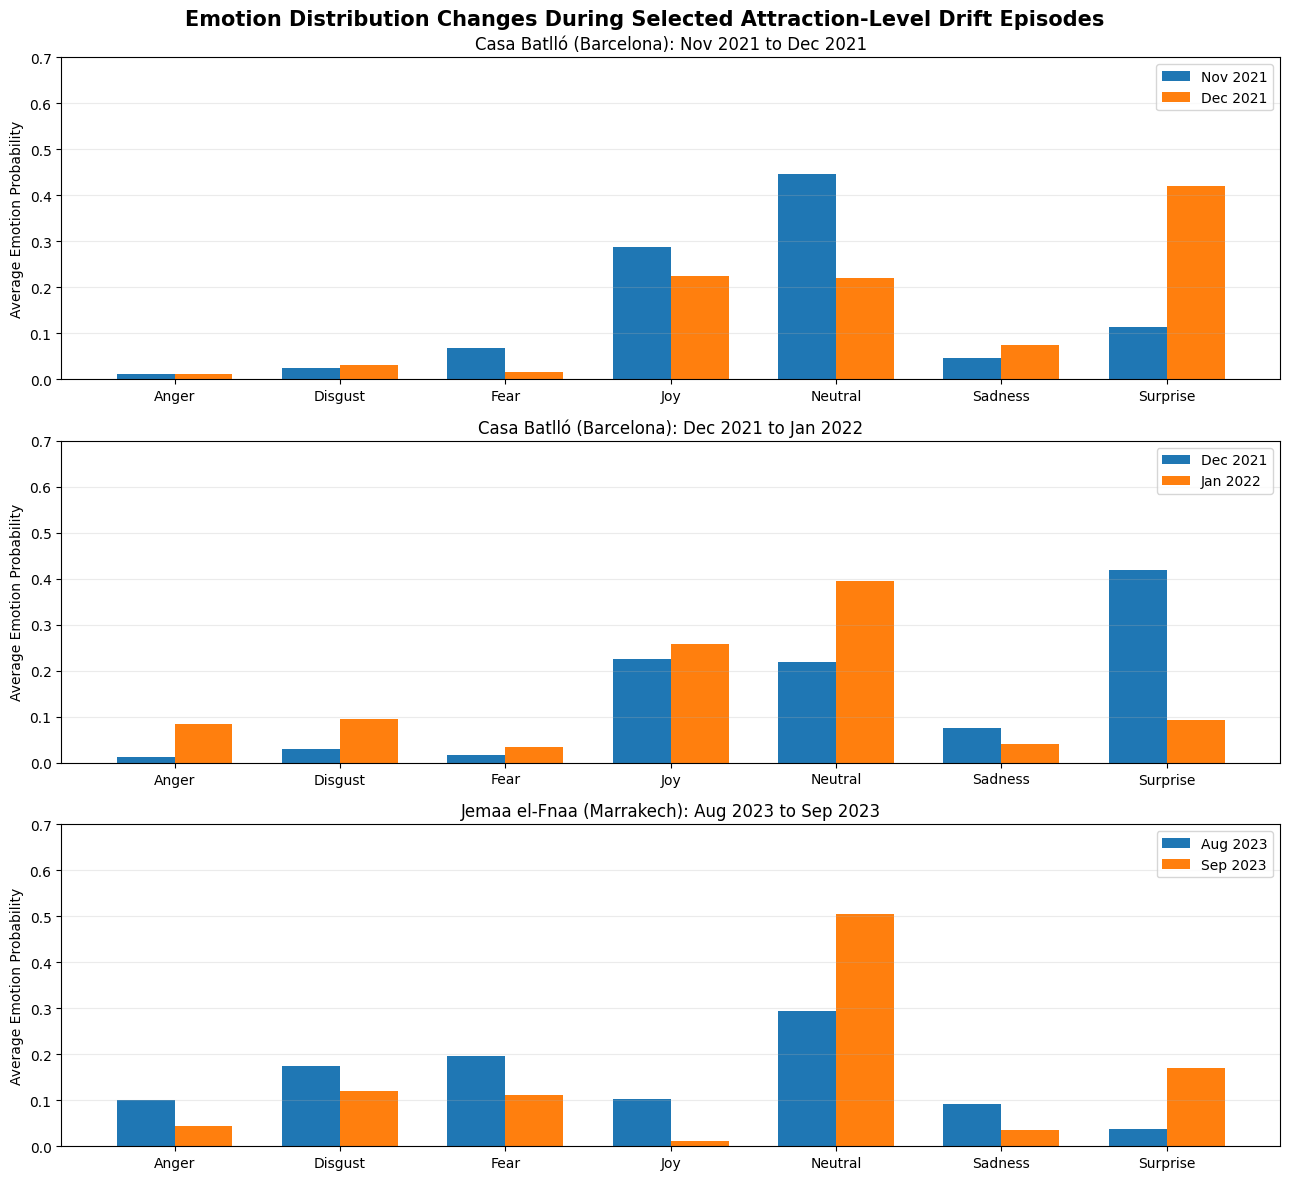

In [47]:

import matplotlib.pyplot as plt
import numpy as np

# Three selected drift episodes
episodes = [
    ("Barcelona", "Casa Batlló", "2021-12-01"),
    ("Barcelona", "Casa Batlló", "2022-01-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-09-01")
]

fig, axes = plt.subplots(3, 1, figsize=(13, 12))

x = np.arange(len(emotion_cols))
width = 0.35

for ax, (city, place, current_month) in zip(axes, episodes):

    current_month = pd.Timestamp(current_month)

    episode_data = emotion_changes_df[
        (emotion_changes_df["City"] == city) &
        (emotion_changes_df["Place"] == place) &
        (emotion_changes_df["Current_Month"] == current_month)
    ].set_index("Emotion").reindex(emotion_cols)

    previous_values = episode_data[
        "Previous_Probability"
    ].to_numpy()

    current_values = episode_data[
        "Current_Probability"
    ].to_numpy()

    previous_month = episode_data[
        "Previous_Month"
    ].iloc[0]

    ax.bar(
        x - width / 2,
        previous_values,
        width,
        label=previous_month.strftime("%b %Y")
    )

    ax.bar(
        x + width / 2,
        current_values,
        width,
        label=current_month.strftime("%b %Y")
    )

    ax.set_title(
        f"{place} ({city}): "
        f"{previous_month.strftime('%b %Y')} to "
        f"{current_month.strftime('%b %Y')}"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(emotion_cols)
    ax.set_ylabel("Average Emotion Probability")
    ax.set_ylim(0, 0.7)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Emotion Distribution Changes During "
    "Selected Attraction-Level Drift Episodes",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Attraction_Emotion_Changes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Step 16: Review Volume Around Selected Drift Episodes

This step examines the number of reviews available before and after each selected attraction-level drift episode.

Review volume is important because emotion distributions based on a small number of reviews may fluctuate more strongly.

We compare the monthly review counts for Casa Batlló in Barcelona and Jemaa el-Fnaa in Marrakech.

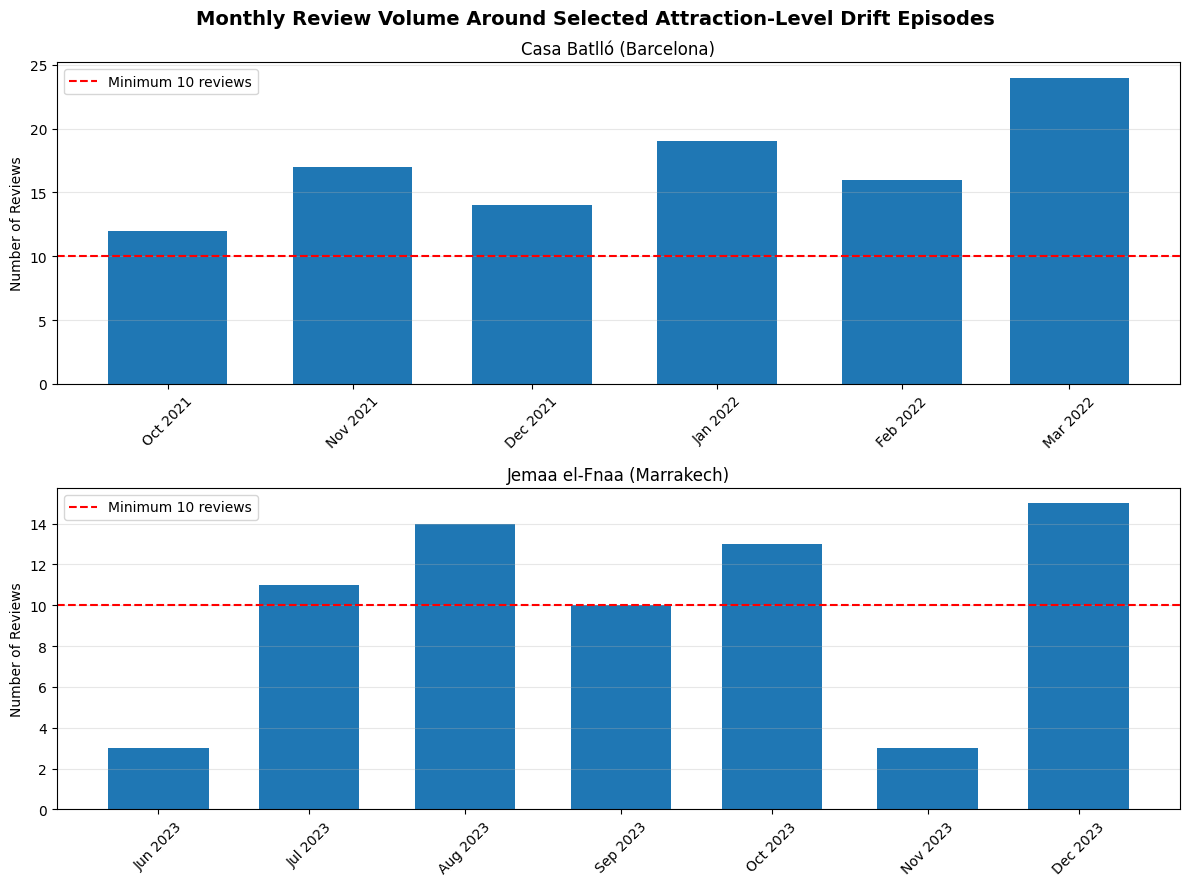

In [48]:

import pandas as pd
import matplotlib.pyplot as plt

selected_places = [
    ("Barcelona", "Casa Batlló", "2021-10-01", "2022-03-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-06-01", "2023-12-01")
]

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for ax, (city, place, start, end) in zip(axes, selected_places):

    data = monthly_place[
        (monthly_place["City"] == city) &
        (monthly_place["Place"] == place) &
        (monthly_place["Month_Year"] >= pd.Timestamp(start)) &
        (monthly_place["Month_Year"] <= pd.Timestamp(end))
    ].copy()

    # Include months with zero reviews
    months = pd.date_range(start, end, freq="MS")

    data = (
        data.set_index("Month_Year")
        .reindex(months)
    )

    data["Review_Count"] = data["Review_Count"].fillna(0)

    ax.bar(
        data.index,
        data["Review_Count"],
        width=20
    )

    ax.axhline(
        y=10,
        color="red",
        linestyle="--",
        label="Minimum 10 reviews"
    )

    ax.set_title(f"{place} ({city})")
    ax.set_ylabel("Number of Reviews")
    ax.set_xticks(months)
    ax.set_xticklabels(
        [m.strftime("%b %Y") for m in months],
        rotation=45
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Monthly Review Volume Around Selected Attraction-Level Drift Episodes",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Step 17: Comparison of Attraction-Level and City-Level Emotional Drift

This step compares emotional drift at individual tourist attractions with emotional drift across their cities.

The aim is to examine whether changes observed at a particular attraction are also visible in the overall city-level emotion distribution.

We compare three selected attraction-level episodes using Jensen-Shannon distance.

In [49]:

import pandas as pd

# Load existing city-level drift results
city_drift = pd.read_csv(
    "results/Emotional_Drift_Results.csv"
)

# Selected attraction-level episodes
selected = [
    ("Barcelona", "Casa Batlló", "2021-12-01"),
    ("Barcelona", "Casa Batlló", "2022-01-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-09-01")
]

# Standardize date columns
city_drift["Month_Year"] = pd.to_datetime(
    city_drift["Month_Year"]
)

place_drift["Month_Year"] = pd.to_datetime(
    place_drift["Month_Year"]
)

comparison_rows = []

for city, place, month in selected:

    month = pd.Timestamp(month)

    attraction = place_drift[
        (place_drift["City"] == city) &
        (place_drift["Place"] == place) &
        (place_drift["Month_Year"] == month)
    ]

    city_result = city_drift[
        (city_drift["City"] == city) &
        (city_drift["Month_Year"] == month)
    ]

    if attraction.empty:
        continue

    attraction_js = attraction["JS_Drift"].iloc[0]

    city_js = (
        city_result["JS_Drift"].iloc[0]
        if not city_result.empty
        else float("nan")
    )

    comparison_rows.append({
        "City": city,
        "Attraction": place,
        "Month": month.strftime("%Y-%m"),
        "Attraction_JS": attraction_js,
        "City_JS": city_js
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(4))


,City,Attraction,Month,Attraction_JS,City_JS
0,Barcelona,Casa Batlló,2021-12,0.3363,0.2352
1,Barcelona,Casa Batlló,2022-01,0.3726,0.2402
2,Marrakech,Jemaa el-Fnaa,2023-09,0.3359,0.0999


### Step 18: Comparison of Attraction-Level and City-Level Drift

This figure compares Jensen-Shannon distance at selected tourist attractions with the corresponding city-level distance.

The aim is to understand whether emotional changes at individual attractions are also reflected in the overall city-level emotion distribution.

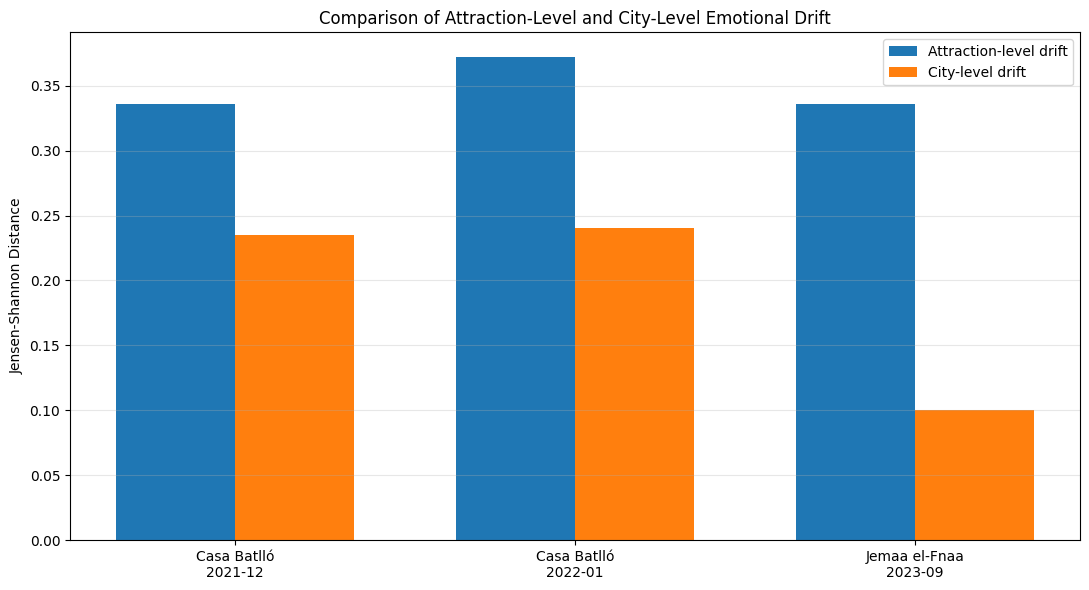

In [50]:

import matplotlib.pyplot as plt
import numpy as np

labels = (
    comparison_df["Attraction"] +
    "\n" +
    comparison_df["Month"]
)

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    comparison_df["Attraction_JS"],
    width,
    label="Attraction-level drift"
)

ax.bar(
    x + width / 2,
    comparison_df["City_JS"],
    width,
    label="City-level drift"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel("Jensen-Shannon Distance")
ax.set_title(
    "Comparison of Attraction-Level and City-Level Emotional Drift"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Attraction_vs_City_Drift.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Step 19: Attraction Contribution to City Review Volume

This step calculates the percentage of city reviews contributed by selected tourist attractions during emotional drift episodes.

The purpose is to understand the relative size of each attraction in the city dataset and provide context for the differences between attraction-level and city-level emotional drift.

In [51]:

# Calculate city-level monthly review counts
city_monthly_counts = (
    place_df.groupby(["City", "Month_Year"])
    .size()
    .reset_index(name="City_Review_Count")
)

# Calculate attraction-level monthly review counts
attraction_monthly_counts = (
    place_df.groupby(["City", "Place", "Month_Year"])
    .size()
    .reset_index(name="Attraction_Review_Count")
)

# Combine the counts
contribution_df = attraction_monthly_counts.merge(
    city_monthly_counts,
    on=["City", "Month_Year"],
    how="left"
)

# Calculate attraction share
contribution_df["Attraction_Share_Percent"] = (
    contribution_df["Attraction_Review_Count"] /
    contribution_df["City_Review_Count"] * 100
)

# Select the three drift episodes
selected_months = [
    ("Barcelona", "Casa Batlló", "2021-12-01"),
    ("Barcelona", "Casa Batlló", "2022-01-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-09-01")
]

selected_rows = []

for city, place, month in selected_months:

    result = contribution_df[
        (contribution_df["City"] == city) &
        (contribution_df["Place"] == place) &
        (contribution_df["Month_Year"] == pd.Timestamp(month))
    ]

    selected_rows.append(result)

selected_contribution = pd.concat(
    selected_rows,
    ignore_index=True
)

display(
    selected_contribution[
        [
            "City",
            "Place",
            "Month_Year",
            "Attraction_Review_Count",
            "City_Review_Count",
            "Attraction_Share_Percent"
        ]
    ].round(2)
)


,City,Place,Month_Year,Attraction_Review_Count,City_Review_Count,Attraction_Share_Percent
0,Barcelona,Casa Batlló,2021-12-01,14,18,77.78
1,Barcelona,Casa Batlló,2022-01-01,19,31,61.29
2,Marrakech,Jemaa el-Fnaa,2023-09-01,10,37,27.03


### Step 20: Leave-One-Attraction-Out Analysis

This step examines how selected attractions influence the overall city-level emotion distribution.

For each selected episode, we calculate city-level Jensen-Shannon distance using all reviews and then recalculate it after excluding the selected attraction.

This helps assess whether the observed city-level emotional change is mainly associated with one attraction or is also present across the remaining attractions.

In [52]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon

selected_episodes = [
    ("Barcelona", "Casa Batlló", "2021-12-01"),
    ("Barcelona", "Casa Batlló", "2022-01-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-09-01")
]

results = []

for city, place, current_month in selected_episodes:

    current_month = pd.Timestamp(current_month)
    previous_month = current_month - pd.DateOffset(months=1)

    city_reviews = place_df[
        (place_df["City"] == city) &
        (place_df["Month_Year"].isin(
            [previous_month, current_month]
        ))
    ].copy()

    remaining_reviews = city_reviews[
        city_reviews["Place"] != place
    ].copy()

    def calculate_drift(data):
        previous = data[
            data["Month_Year"] == previous_month
        ]

        current = data[
            data["Month_Year"] == current_month
        ]

        if previous.empty or current.empty:
            return np.nan

        previous_profile = previous[emotion_cols].mean().to_numpy()
        current_profile = current[emotion_cols].mean().to_numpy()

        return jensenshannon(
            previous_profile,
            current_profile,
            base=2
        )

    all_city_js = calculate_drift(city_reviews)
    without_js = calculate_drift(remaining_reviews)

    results.append({
        "City": city,
        "Excluded_Attraction": place,
        "Month": current_month.strftime("%Y-%m"),
        "City_JS_All": all_city_js,
        "City_JS_Without_Attraction": without_js,
        "Remaining_Reviews_Previous": len(
            remaining_reviews[
                remaining_reviews["Month_Year"] == previous_month
            ]
        ),
        "Remaining_Reviews_Current": len(
            remaining_reviews[
                remaining_reviews["Month_Year"] == current_month
            ]
        )
    })

leave_one_out_df = pd.DataFrame(results)

leave_one_out_df["JS_Difference"] = (
    leave_one_out_df["City_JS_All"] -
    leave_one_out_df["City_JS_Without_Attraction"]
)

display(leave_one_out_df.round(4))


,City,Excluded_Attraction,Month,City_JS_All,City_JS_Without_Attraction,Remaining_Reviews_Previous,Remaining_Reviews_Current,JS_Difference
0,Barcelona,Casa Batlló,2021-12,0.2825,0.2479,24,4,0.0346
1,Barcelona,Casa Batlló,2022-01,0.2885,0.3243,4,12,-0.0358
2,Marrakech,Jemaa el-Fnaa,2023-09,0.1200,0.1678,49,27,-0.0478


### Step 21: Validation of City-Level Jensen-Shannon Distance

This step checks whether the differences between the city-level and attraction-level notebooks are caused by different Jensen-Shannon distance settings.

The same calculation method should be used throughout the analysis to ensure consistent results.

In [53]:

from scipy.spatial.distance import jensenshannon
import numpy as np
import pandas as pd

validation_rows = []

for city, place, current_month in selected_episodes:

    current_month = pd.Timestamp(current_month)
    previous_month = current_month - pd.DateOffset(months=1)

    previous_reviews = place_df[
        (place_df["City"] == city) &
        (place_df["Month_Year"] == previous_month)
    ]

    current_reviews = place_df[
        (place_df["City"] == city) &
        (place_df["Month_Year"] == current_month)
    ]

    previous_profile = previous_reviews[emotion_cols].mean().to_numpy()
    current_profile = current_reviews[emotion_cols].mean().to_numpy()

    js_base2 = jensenshannon(
        previous_profile,
        current_profile,
        base=2
    )

    js_natural = jensenshannon(
        previous_profile,
        current_profile
    )

    validation_rows.append({
        "City": city,
        "Month": current_month.strftime("%Y-%m"),
        "JS_Base_2": js_base2,
        "JS_Natural_Log": js_natural
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.round(4))


,City,Month,JS_Base_2,JS_Natural_Log
0,Barcelona,2021-12,0.2825,0.2352
1,Barcelona,2022-01,0.2885,0.2402
2,Marrakech,2023-09,0.1200,0.0999


## Step 22: Standardizing Jensen–Shannon Distance

Jensen–Shannon distance is calculated using logarithm base 2.

This ensures that city-level and attraction-level emotional drift
are measured using the same method.

The distance ranges from 0 to 1.

In [54]:
import numpy as np
import pandas as pd

# Previously calculated city-level comparison
# Expected columns: City, Attraction, Month,
# Attraction_JS, City_JS

comparison_base2 = comparison_df.copy()

# Conversion from natural-log JS distance to base-2 JS distance
conversion_factor = 1 / np.sqrt(np.log(2))

comparison_base2["City_JS_Base2"] = (
    comparison_base2["City_JS"] * conversion_factor
)

comparison_base2["Attraction_JS_Base2"] = (
    comparison_base2["Attraction_JS"]
)

# Display comparison
display(
    comparison_base2[
        [
            "City",
            "Attraction",
            "Month",
            "Attraction_JS_Base2",
            "City_JS_Base2"
        ]
    ].round(4)
)

,City,Attraction,Month,Attraction_JS_Base2,City_JS_Base2
0,Barcelona,Casa Batlló,2021-12,0.3363,0.2825
1,Barcelona,Casa Batlló,2022-01,0.3726,0.2885
2,Marrakech,Jemaa el-Fnaa,2023-09,0.3359,0.1200


In [55]:
print("Maximum city-level JS distance:",
      comparison_base2["City_JS_Base2"].max())

print("Maximum attraction-level JS distance:",
      comparison_base2["Attraction_JS_Base2"].max())

assert comparison_base2["City_JS_Base2"].between(0, 1).all()
assert comparison_base2["Attraction_JS_Base2"].between(0, 1).all()

print("Jensen–Shannon distance validation passed.")

Maximum city-level JS distance: 0.28847995485617633
Maximum attraction-level JS distance: 0.3725630512098592
Jensen–Shannon distance validation passed.


## Step 23: Permutation Testing

Permutation testing is used to evaluate whether the observed
emotional drift between two consecutive months is unusually large.

The test randomly rearranges reviews between the two months
while preserving the original number of reviews in each month.

A p-value below 0.05 indicates evidence of a difference
between the monthly emotion distributions.

The results will be interpreted cautiously because several
drift episodes have been examined.

In [56]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon

episodes = [
    ("Barcelona", "Casa Batlló", "2021-11", "2021-12"),
    ("Barcelona", "Casa Batlló", "2021-12", "2022-01"),
    ("Marrakech", "Jemaa el-Fnaa", "2023-08", "2023-09")
]

rng = np.random.default_rng(42)
n_permutations = 5000

results = []

place_df["Month_Year"] = pd.to_datetime(
    place_df["Month_Year"]
)

for city, place, previous_month, current_month in episodes:

    previous = place_df[
        (place_df["City"] == city) &
        (place_df["Place"] == place) &
        (place_df["Month_Year"].dt.strftime("%Y-%m") == previous_month)
    ][emotion_cols].to_numpy(dtype=float)

    current = place_df[
        (place_df["City"] == city) &
        (place_df["Place"] == place) &
        (place_df["Month_Year"].dt.strftime("%Y-%m") == current_month)
    ][emotion_cols].to_numpy(dtype=float)

    if len(previous) == 0 or len(current) == 0:
        print("Missing reviews:", city, place, current_month)
        continue

    observed_js = jensenshannon(
        previous.mean(axis=0),
        current.mean(axis=0),
        base=2
    )

    combined = np.vstack([previous, current])
    n_previous = len(previous)

    permutation_distances = []

    for _ in range(n_permutations):

        shuffled = rng.permutation(len(combined))

        group_1 = combined[shuffled[:n_previous]]
        group_2 = combined[shuffled[n_previous:]]

        perm_js = jensenshannon(
            group_1.mean(axis=0),
            group_2.mean(axis=0),
            base=2
        )

        permutation_distances.append(perm_js)

    permutation_distances = np.array(permutation_distances)

    p_value = (
        np.sum(permutation_distances >= observed_js) + 1
    ) / (n_permutations + 1)

    results.append({
        "City": city,
        "Place": place,
        "Previous_Month": previous_month,
        "Current_Month": current_month,
        "Previous_Reviews": len(previous),
        "Current_Reviews": len(current),
        "Observed_JS": observed_js,
        "Permutation_Mean_JS": permutation_distances.mean(),
        "P_Value": p_value
    })

permutation_results = pd.DataFrame(results)

display(permutation_results.round(4))

,City,Place,Previous_Month,Current_Month,Previous_Reviews,Current_Reviews,Observed_JS,Permutation_Mean_JS,P_Value
0,Barcelona,Casa Batlló,2021-11,2021-12,17,14,0.3363,0.2289,0.0528
1,Barcelona,Casa Batlló,2021-12,2022-01,14,19,0.3726,0.2217,0.0116
2,Marrakech,Jemaa el-Fnaa,2023-08,2023-09,14,10,0.3359,0.3031,0.2901


## Step 24: Multiple-Testing Correction

The permutation tests were evaluated using the
Benjamini-Hochberg False Discovery Rate (FDR) correction.

This correction helps control false discoveries when
multiple statistical tests are performed.

The adjusted p-values are compared with a significance
level of 0.05.

Because the episodes were selected after examining
the drift results, these tests are treated as exploratory.

In [57]:
import numpy as np
import pandas as pd

# Copy permutation results
fdr_results = permutation_results.copy()

# Benjamini-Hochberg correction
p_values = fdr_results["P_Value"].to_numpy(dtype=float)

m = len(p_values)
order = np.argsort(p_values)

sorted_p = p_values[order]

adjusted_sorted = sorted_p * m / np.arange(1, m + 1)

adjusted_sorted = np.minimum.accumulate(
    adjusted_sorted[::-1]
)[::-1]

adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

adjusted_p = np.empty(m)
adjusted_p[order] = adjusted_sorted

fdr_results["FDR_Adjusted_P"] = adjusted_p

fdr_results["Significant_After_FDR"] = (
    fdr_results["FDR_Adjusted_P"] < 0.05
)

display(
    fdr_results[
        [
            "City",
            "Place",
            "Previous_Month",
            "Current_Month",
            "Observed_JS",
            "P_Value",
            "FDR_Adjusted_P",
            "Significant_After_FDR"
        ]
    ].round(4)
)

,City,Place,Previous_Month,Current_Month,Observed_JS,P_Value,FDR_Adjusted_P,Significant_After_FDR
0,Barcelona,Casa Batlló,2021-11,2021-12,0.3363,0.0528,0.0792,False
1,Barcelona,Casa Batlló,2021-12,2022-01,0.3726,0.0116,0.0348,True
2,Marrakech,Jemaa el-Fnaa,2023-08,2023-09,0.3359,0.2901,0.2901,False


## Step 25: Save Analysis Results

The attraction-level emotional drift results are saved as CSV files.

These files include monthly emotion profiles, drift comparisons,
attraction rankings, sensitivity analysis, and permutation tests.

The results will be used for the thesis report and further analysis.

In [59]:
from pathlib import Path
import pandas as pd

output_dir = Path("results/place_level")
output_dir.mkdir(parents=True, exist_ok=True)

# Find the attraction-level drift dataframe
required_columns = {
    "City", "Place", "Previous_Month",
    "Month_Year", "JS_Drift", "Cosine_Drift"
}

candidates = [
    (name, value)
    for name, value in globals().copy().items()
    if isinstance(value, pd.DataFrame)
    and required_columns.issubset(value.columns)
    and len(value) == 950
]

# Use the original attraction-level drift dataframe
attraction_drift = place_drift.copy()

print("Using drift dataframe: place_drift")
print("Total comparisons:", len(attraction_drift))

print("Using drift dataframe:", drift_name)

# Save monthly emotion profiles
monthly_place.to_csv(
    output_dir / "Monthly_Attraction_Emotion_Profiles.csv",
    index=False
)

# Save attraction drift results
attraction_drift.to_csv(
    output_dir / "Attraction_Emotional_Drift.csv",
    index=False
)

# Save threshold sensitivity
sensitivity_summary.to_csv(
    output_dir / "Attraction_Threshold_Sensitivity.csv",
    index=False
)

# Save detected spikes
threshold_spikes.to_csv(
    output_dir / "Attraction_Drift_Spikes.csv",
    index=False
)

# Save permutation and FDR results
fdr_results.to_csv(
    output_dir / "Attraction_Permutation_FDR.csv",
    index=False
)

print("\nAll attraction-level results saved successfully.")

for file in sorted(output_dir.glob("*.csv")):
    print(file.name)

Using drift dataframe: place_drift
Total comparisons: 950
Using drift dataframe: place_drift

All attraction-level results saved successfully.
Attraction_Drift_Spikes.csv
Attraction_Emotional_Drift.csv
Attraction_Permutation_FDR.csv
Attraction_Threshold_Sensitivity.csv
Monthly_Attraction_Emotion_Profiles.csv


## Step 26: Findings and Limitations

### Main Findings

The attraction-level analysis examined 48 tourist attractions
across 10 destinations from 2019 to 2024.

Using a minimum of 5 reviews per month, 950 consecutive-month
comparisons were available.

Fourteen extreme drift candidates were identified among 923
eligible comparisons.

At a minimum of 10 reviews per month, three extreme drift
candidates were identified among 254 eligible comparisons.

The selected episodes included Casa Batlló in Barcelona and
Jemaa el-Fnaa in Marrakech.

Permutation testing found evidence of an emotion-distribution
difference for Casa Batlló between December 2021 and January
2022 (p = 0.0116).

The adjusted p-value across the three selected tests was 0.0348.
However, this result remains exploratory because the episodes
were selected after examining the drift data.

### Limitations

Many attractions had relatively few reviews per month.

The detected spikes changed when different minimum review
thresholds were applied.

No extreme episode was detected at both the 5-review and
10-review thresholds.

The emotion scores were generated by a pretrained language
model and may contain classification errors.

The analysis identifies changes in review emotion distributions
but does not establish their causes.

### Conclusion

Attraction-level analysis provides more detailed information
about emotional changes at individual tourist sites.

However, sparse monthly data and sensitivity to analysis
thresholds limit the strength of the findings.

These results should be interpreted alongside the city-level
analysis rather than as independent evidence of external
event effects.